# TOPIC 1: Explainable Machine Learning for Gallstone Disease
**Member 1 Scope:** Data Loading, Exploratory Data Analysis (EDA), Preprocessing, Cross-Validation, Holdout Evaluation, and Model Export.

## Index of the Notebook
1. **Exploratory Data Analysis (EDA):** Dataset dimensions, target class balance, biomarker distributions, and feature correlations.
2. **Data Preprocessing:** Continuous feature scaling via `ColumnTransformer` and stratified train/test split ($80/20$).
3. **Model Development & Stratified 5-Fold Cross-Validation:** 5-Fold Stratified Cross-Validation using Scikit-Learn `Pipeline` to prevent data leakage.
4. **Holdout Evaluation:** Holdout test performance metrics (Accuracy, Precision, Recall, F1-Score, ROC-AUC) and confusion matrices.
5. **Model Export:** Export of optimal pipeline (`best_model.joblib`) and fitted preprocessor (`scaler.joblib`) for downstream explainability modules.

In [49]:
# NECESSARY LIBRARIES FROM THE COURSE

import os
import warnings
import joblib

# 1.2: Introduction to Python Libraries for Machine Learning
# Data handling, visualization, and preprocessing
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing & Model Selection
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# 3.2.1 & 3.2.5: Classifiers
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier

# 3.2.3: Evaluation Metrics
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix, classification_report
)

warnings.filterwarnings('ignore')

In [50]:
#uploading the dataset from the location of the excel on the project

#dataset route to the excel
data_path = os.path.join('..', 'dataset', 'dataset-uci.xlsx')

#uploading the dataset with calamine
df = pd.read_excel(data_path, engine='calamine')

#printing to check the succes
print(f"Dataset uploaded. Size: {df.shape}")
df.head()

Dataset uploaded. Size: (319, 39)


,Gallstone Status,Age,Gender,Comorbidity,Coronary Artery Disease (CAD),Hypothyroidism,Hyperlipidemia,Diabetes Mellitus (DM),Height,Weight,...,High Density Lipoprotein (HDL),Triglyceride,Aspartat Aminotransferaz (AST),Alanin Aminotransferaz (ALT),Alkaline Phosphatase (ALP),Creatinine,Glomerular Filtration Rate (GFR),C-Reactive Protein (CRP),Hemoglobin (HGB),Vitamin D
0,0,50,0,0,0,0,0,0,185,92.8,...,40.0,134.0,20.0,22.0,87.0,0.82,112.47,0.0,16.0,33.0
1,0,47,0,1,0,0,0,0,176,94.5,...,43.0,103.0,14.0,13.0,46.0,0.87,107.10,0.0,14.4,25.0
2,0,61,0,0,0,0,0,0,171,91.1,...,43.0,69.0,18.0,14.0,66.0,1.25,65.51,0.0,16.2,30.2
3,0,41,0,0,0,0,0,0,168,67.7,...,59.0,53.0,20.0,12.0,34.0,1.02,94.10,0.0,15.4,35.4
4,0,42,0,0,0,0,0,0,178,89.6,...,30.0,326.0,27.0,54.0,71.0,0.82,112.47,0.0,16.8,40.6


1. **Exploratory Data Analysis (EDA):** Dataset dimensions, target class balance, biomarker distributions, and feature correlations.

Total missing values: 0

Target Class Distribution:
Gallstone Status
0    161
1    158
Name: count, dtype: int64


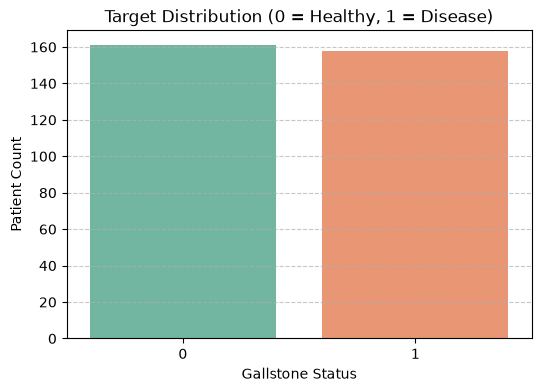

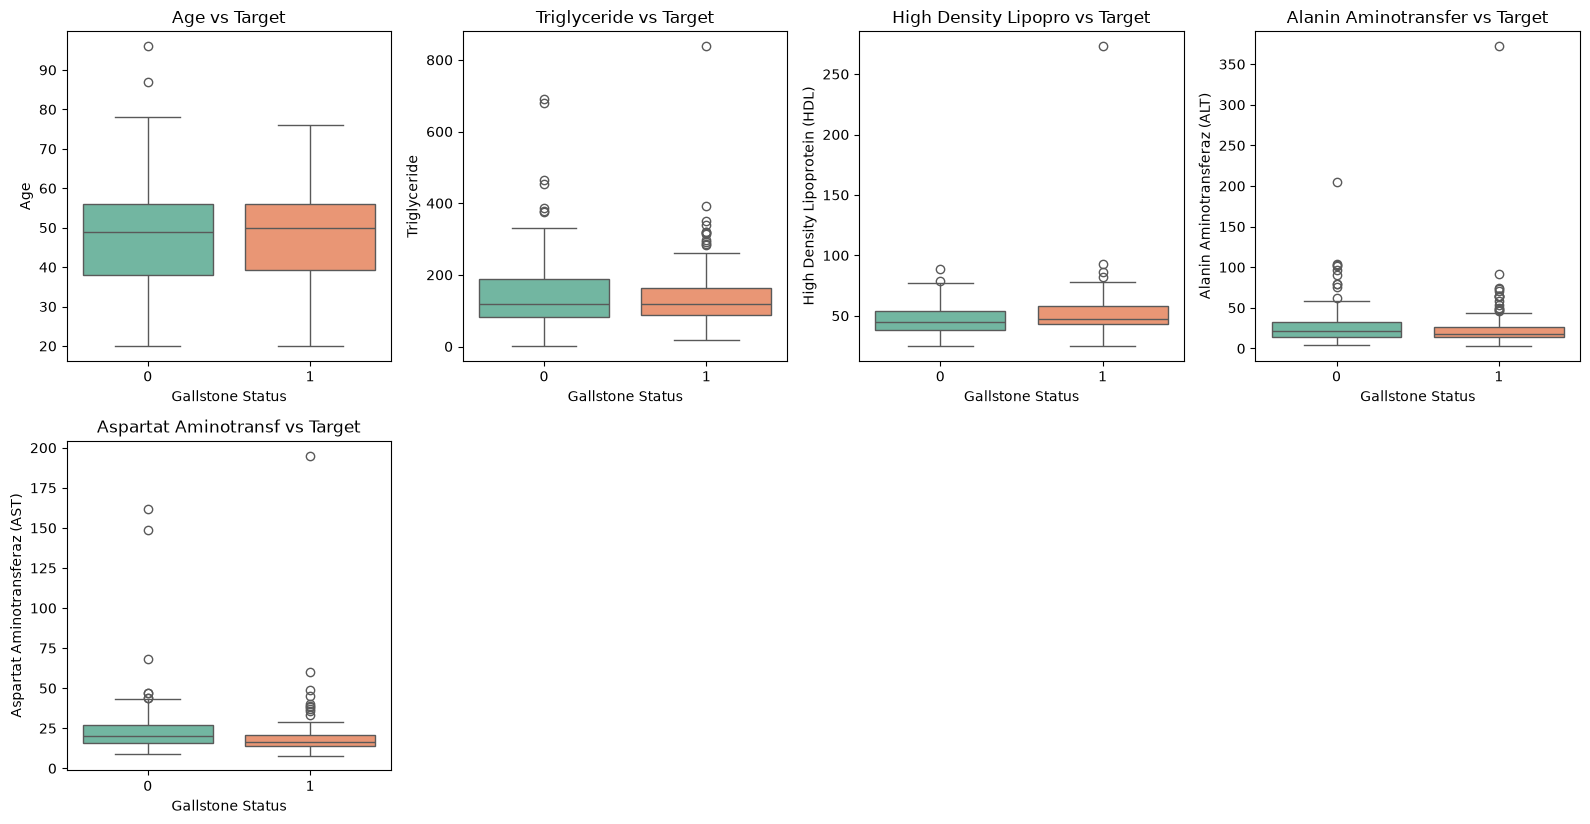

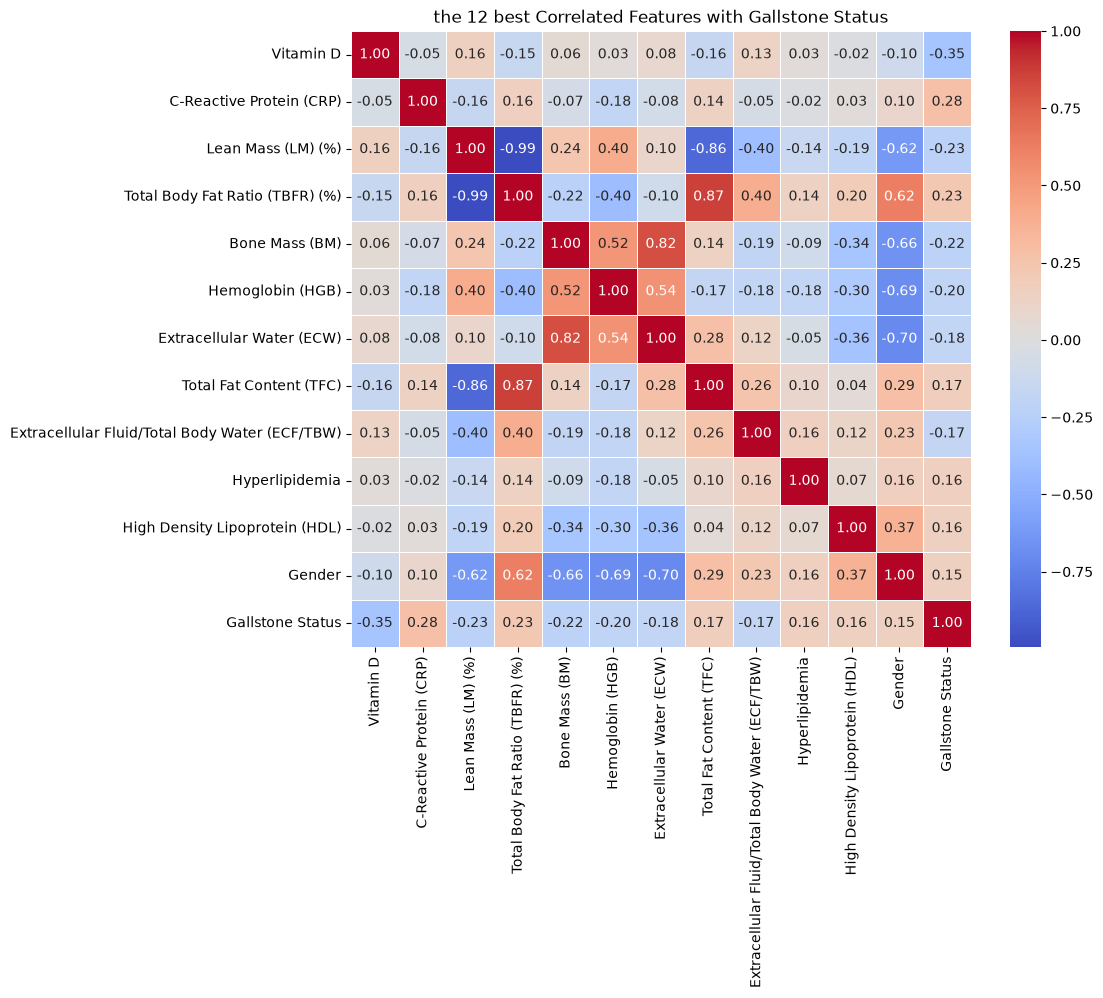

In [51]:
#setting the target
target_col = 'Gallstone Status'

#data Integrity & Missing Values
print(f"Total missing values: {df.isnull().sum().sum()}")

#target Variable Class Balance
print("\nTarget Class Distribution:")
print(df[target_col].value_counts())

#plotting class balance
plt.figure(figsize=(6, 4))
sns.countplot(x=target_col, data=df, hue=target_col, palette='Set2', legend=False)
plt.title('Target Distribution (0 = Healthy, 1 = Disease)')
plt.xlabel('Gallstone Status')
plt.ylabel('Patient Count')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

#biomarker Distributions through Classes
key_features = [
    'Age', 'BMI', 'Triglyceride', 'High Density Lipoprotein (HDL)', 
    'Total Cholesterol', 'Alanin Aminotransferaz (ALT)', 'Aspartat Aminotransferaz (AST)',
    'Total Fat Content', 'Visceral Fat Area', 'Lean Mass', 'Total Body Fat Ratio'
]
existing_features = [f for f in key_features if f in df.columns]

#plotting the distributions
plt.figure(figsize=(16, 12)) #we make it big enough for the 12 features to fit
for i, col in enumerate(existing_features, 1):
    plt.subplot(3, 4, i)
    #box graphic
    sns.boxplot(x=target_col, y=col, data=df, palette='Set2', hue=target_col, legend=False)
    plt.title(f'{col[:20]} vs Target')
plt.tight_layout()
plt.show()

#Correlation Heatmap (best 12 Features)
plt.figure(figsize=(10, 8))
corr_with_target = df.corr()[target_col].drop(target_col).abs()
top_12_features = corr_with_target.sort_values(ascending=False).head(12).index

#plotting the heatmap
heatmap_vars = list(top_12_features) + [target_col]
sns.heatmap(df[heatmap_vars].corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('the 12 best Correlated Features with Gallstone Status')
plt.show()

2. **Data Preprocessing:** Continuous feature scaling via `ColumnTransformer` and stratified train/test split ($80/20$).

In [52]:
#separate features and target
X = df.drop(columns=[target_col])
y = df[target_col]

#identify continuous agaisnt binary features
continuous_cols = [c for c in X.columns if X[c].nunique() > 2 and X[c].dtype in ['int64', 'float64']]
binary_cols = [c for c in X.columns if c not in continuous_cols]

#define scales continuous features only
preprocessor = ColumnTransformer(
    transformers=[('num', StandardScaler(), continuous_cols)],
    remainder='passthrough'
)

#stratified Train/Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Data preprocessing setup complete:")
print(f" Train set: {X_train.shape[0]} samples")
print(f" Test set:  {X_test.shape[0]} samples")
print(f" Continuous features to scale: {len(continuous_cols)}")
print(f" Binary features preserved:  {len(binary_cols)}")

Data preprocessing setup complete:
 Train set: 255 samples
 Test set:  64 samples
 Continuous features to scale: 33
 Binary features preserved:  5


3. **Model Development & Stratified 5-Fold Cross-Validation:** 5-Fold Stratified Cross-Validation using Scikit-Learn `Pipeline` to prevent data leakage.

In [53]:
#dictionary of the different models
models = {
    'Logistic Regression': LogisticRegression(random_state=42, max_iter=1000),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'Support Vector Machine': SVC(probability=True, random_state=42),
    'XGBoost': XGBClassifier(eval_metric='logloss', random_state=42)
}

#defining 5-Fold Stratified cross-validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

#list to store the results
cv_results = {}

print("Running 5-Fold Stratified Cross-Validation")
for name, model in models.items():
    #pipeline wraps preprocessing and model to prevent data leakage
    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])
    
    scores = cross_validate(
        pipeline, X_train, y_train,
        cv=cv, scoring=scoring, return_train_score=False
    )

    #storing the model info (added Standard Deviations for all metrics)
    cv_results[name] = {
        'Accuracy (Mean)': np.mean(scores['test_accuracy']),
        'Accuracy (Std)': np.std(scores['test_accuracy']),
        'Precision (Mean)': np.mean(scores['test_precision']),
        'Precision (Std)': np.std(scores['test_precision']),
        'Recall (Mean)': np.mean(scores['test_recall']),
        'Recall (Std)': np.std(scores['test_recall']),
        'F1-Score (Mean)': np.mean(scores['test_f1']),
        'F1-Score (Std)': np.std(scores['test_f1']),
        'ROC-AUC (Mean)': np.mean(scores['test_roc_auc']),
        'ROC-AUC (Std)': np.std(scores['test_roc_auc'])
    }

#summary DataFrame sorted by mean F1-Score
cv_summary_df = pd.DataFrame(cv_results).T.sort_values(by='F1-Score (Mean)', ascending=False)
print("\n5-Fold Cross-Validation Results Summary:")
display(cv_summary_df.round(4))

#selecting the best model based on CV (Methodologically correct)
best_cv_model_name = cv_summary_df.index[0]
print(f"\nBest model selected by Cross-Validation: {best_cv_model_name}")

Running 5-Fold Stratified Cross-Validation

5-Fold Cross-Validation Results Summary:


,Accuracy (Mean),Accuracy (Std),Precision (Mean),Precision (Std),Recall (Mean),Recall (Std),F1-Score (Mean),F1-Score (Std),ROC-AUC (Mean),ROC-AUC (Std)
Random Forest,0.7529,0.0590,0.7429,0.0643,0.7702,0.0572,0.7555,0.0561,0.8383,0.0538
XGBoost,0.7490,0.0532,0.7507,0.0544,0.7388,0.0793,0.7431,0.0585,0.8335,0.0512
Logistic Regression,0.7333,0.0505,0.7719,0.0690,0.6594,0.0653,0.7093,0.0549,0.8240,0.0547
Support Vector Machine,0.6745,0.0640,0.6966,0.0941,0.6342,0.0716,0.6583,0.0583,0.7603,0.0678



Best model selected by Cross-Validation: Random Forest


4. **Holdout Evaluation:** Holdout test performance metrics (Accuracy, Precision, Recall, F1-Score, ROC-AUC) and confusion matrices.

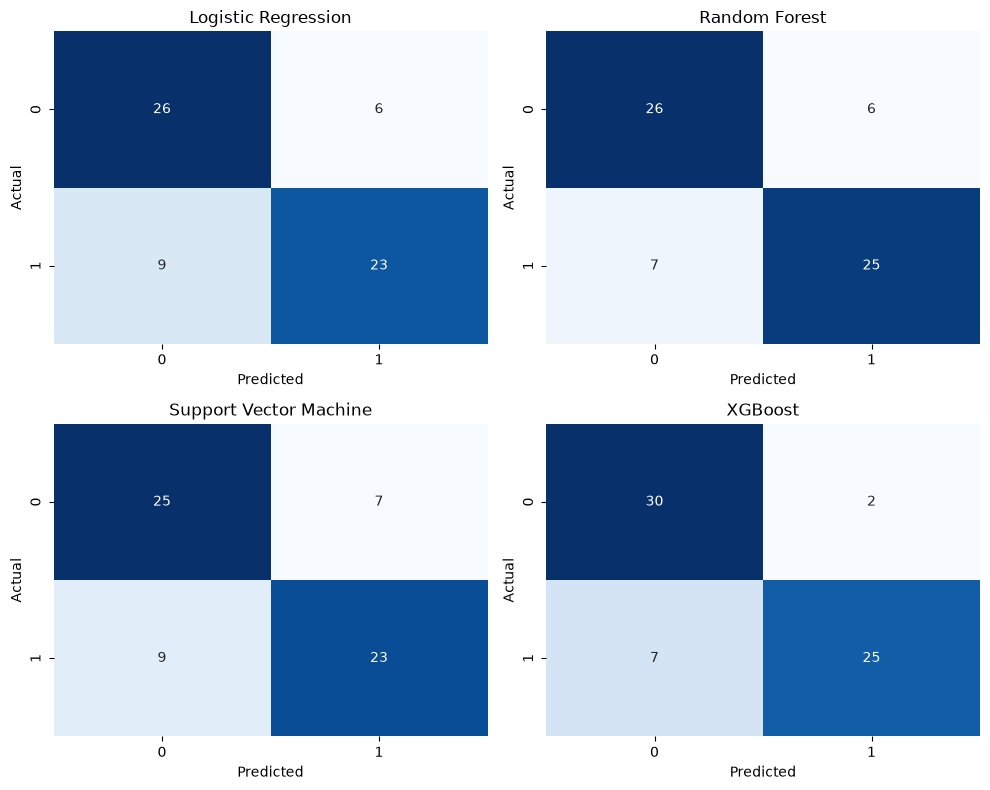


Holdout Test Performance Summary:


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,XGBoost,0.8594,0.9259,0.7812,0.8475,0.8916
1,Random Forest,0.7969,0.8065,0.7812,0.7937,0.8701
2,Logistic Regression,0.7656,0.7931,0.7188,0.7541,0.8779
3,Support Vector Machine,0.7500,0.7667,0.7188,0.7419,0.8994


In [54]:
#lists for the pipelines and results
holdout_results = []
fitted_pipelines = {}

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.flatten()

#looping through the models
for idx, (name, model) in enumerate(models.items()):
    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])
    
    #fitting pipeline on full train set
    pipeline.fit(X_train, y_train)
    fitted_pipelines[name] = pipeline
    
    #predictions on holdout test set
    y_pred = pipeline.predict(X_test)
    y_proba = pipeline.predict_proba(X_test)[:, 1]
    
    holdout_results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-Score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_proba)
    })
    
    #confusion Matrix Heatmap
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx], cbar=False)
    axes[idx].set_title(f'{name}')
    axes[idx].set_xlabel('Predicted')
    axes[idx].set_ylabel('Actual')

#plotting the matrix results
plt.tight_layout()
plt.show()

#holdout Summary DataFrame
holdout_df = pd.DataFrame(holdout_results).sort_values(by='F1-Score', ascending=False).reset_index(drop=True)
print("\nHoldout Test Performance Summary:")
display(holdout_df.round(4))

5. **Model Export:** Export of optimal pipeline (`best_model.joblib`) and fitted preprocessor (`scaler.joblib`) for downstream explainability modules.

In [ ]:
#identify best model based on Cross-Validation
best_model_name = best_cv_model_name
best_pipeline = fitted_pipelines[best_model_name]

#define paths in dataset/ directory
best_model_path = os.path.join('..', 'dataset', 'best_model.joblib')
scaler_path = os.path.join('..', 'dataset', 'scaler.joblib')

#save fitted model pipeline and preprocessor
joblib.dump(best_pipeline, best_model_path)
joblib.dump(preprocessor.fit(X_train), scaler_path)

#get the holdout F1-Score of the selected model to print it
selected_model_test_f1 = holdout_df[holdout_df['Model'] == best_model_name]['F1-Score'].values[0]

#plotting the export
print("Export Complete:")
print(f" Top Model Selected via CV: '{best_model_name}' (Holdout Test F1-Score: {selected_model_test_f1:.4f})")
print(f" Pipeline saved to: {best_model_path}")
print(f" Preprocessor saved to: {scaler_path}")

Export Complete:
 Top Model Selected via CV: 'Random Forest' (Holdout Test F1-Score: 0.7937)
 Pipeline saved to: ..\dataset\best_model.joblib
 Preprocessor saved to: ..\dataset\scaler.joblib
